In [1]:
# TensorFlow and tf.keras
import tensorflow as tf

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt

print(tf.__version__)

2.8.0


In [2]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

4431872/4422102 [==============================] - 0s 0us/step


In [3]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [5]:
train_images.shape

(60000, 28, 28)

In [6]:
len(train_labels)

60000

In [7]:
train_labels

array([9, 0, 0, ..., 3, 0, 5], dtype=uint8)

In [8]:
test_images.shape

(10000, 28, 28)

In [9]:
len(test_labels)

10000

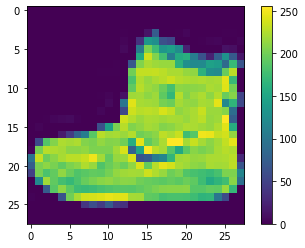

In [11]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

In [16]:
train_images = train_images / 255.0
test_images = test_images / 255.0

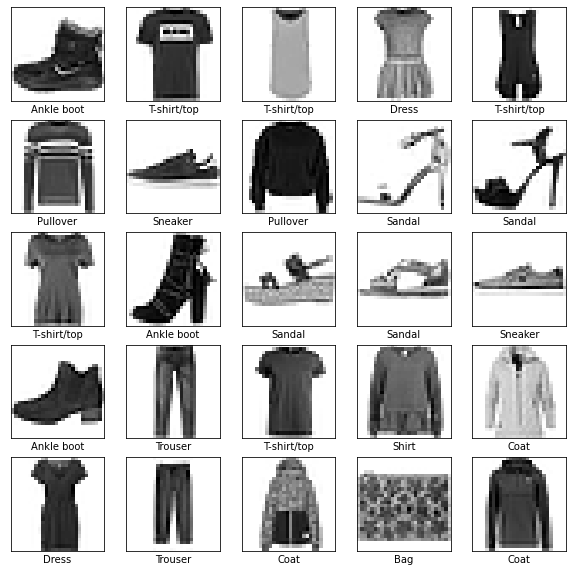

In [17]:
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(train_images[i], cmap= plt.cm.binary)
  plt.xlabel(class_names[train_labels[i]])
plt.show()


**Building the model**

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(128,activation = 'relu'),
    tf.keras.layers.Dense(10),
])

In [19]:
model.compile(
    optimizer = 'adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits = True),
    metrics = ['accuracy']
)

In [20]:
model.fit(train_images,train_labels,epochs=10)

Epoch 1/10
1875/1875 [==============================] - 6s 3ms/step - loss: 1.0772 - accuracy: 0.6645
Epoch 2/10
1875/1875 [==============================] - 5s 3ms/step - loss: 0.6390 - accuracy: 0.7703
Epoch 3/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.5620 - accuracy: 0.7985
Epoch 4/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.5191 - accuracy: 0.8160
Epoch 5/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.4909 - accuracy: 0.8274
Epoch 6/10
1875/1875 [==============================] - 7s 3ms/step - loss: 0.4713 - accuracy: 0.8340
Epoch 7/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.4571 - accuracy: 0.8389
Epoch 8/10
1875/1875 [==============================] - 5s 3ms/step - loss: 0.4457 - accuracy: 0.8431
Epoch 9/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.4365 - accuracy: 0.8461
Epoch 10/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.428

In [22]:
test_loss,test_acc = model.evaluate(test_images,test_labels,verbose = 2)
print('Test Accuracy: ',test_acc)

313/313 - 0s - loss: 0.4596 - accuracy: 0.8342 - 429ms/epoch - 1ms/step
Test Accuracy:  0.8342000246047974


In [23]:
  probability_model = tf.keras.Sequential([
                                           model, tf.keras.layers.Softmax()
  ])

In [24]:
predictions = probability_model.predict(test_images)

In [25]:
predictions[0]

array([4.8933703e-07, 4.0188880e-08, 3.5006829e-06, 6.5228824e-06,
       6.8971035e-06, 1.6608632e-01, 1.6589231e-05, 2.3596796e-01,
       4.5068022e-03, 5.9340489e-01], dtype=float32)

In [26]:
np.argmax(predictions[0])

9

In [28]:
test_labels[0]

9

In [32]:
def plot_image(i,prediction_array,true_label,img):
  true_label, img = true_label[i],img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap= plt.cm.binary)
  predicted_label = np.argmax(prediction_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'
  plt.xlabel("{} {:2.0f}% ({})".format(
      class_names[predicted_label],
      100*np.max(prediction_array),
      class_names[true_label]),
      color = color
  )

In [30]:
def plot_value_array(i,prediction_array,true_label):
  true_label = true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), prediction_array, color = '#777777')
  predicted_label = np.argmax(prediction_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')
  

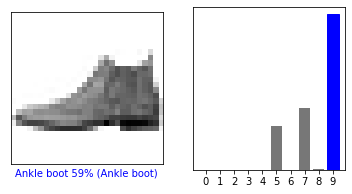

In [33]:
i = 0
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions[i], test_labels,test_images)
plt.subplot(1,2,2)
plot_value_array(i,predictions[i],test_labels)
plt.show()

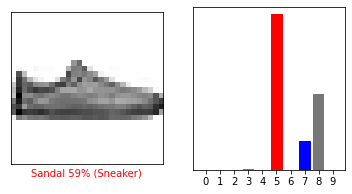

In [34]:
i = 12
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1,2,2)
plot_value_array(i, predictions[i],  test_labels)
plt.show()

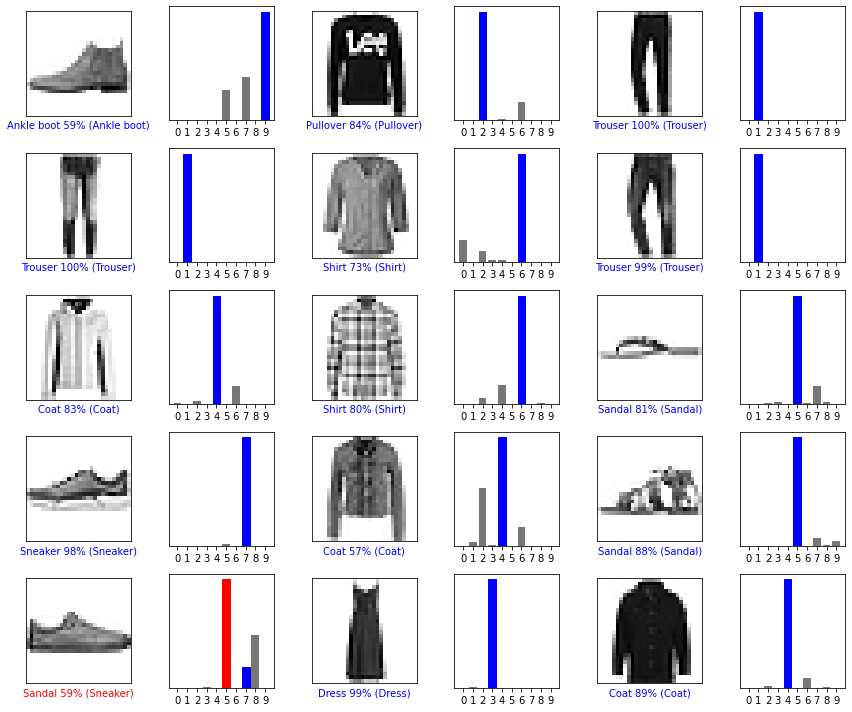

In [35]:
# Plot the first X test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

In [36]:
# Grab an image from the test dataset.
img = test_images[1]

print(img.shape)

(28, 28)


In [37]:
# Add the image to a batch where it's the only member.
img = (np.expand_dims(img,0))

print(img.shape)

(1, 28, 28)


In [38]:
predictions_single = probability_model.predict(img)

print(predictions_single)

[[3.7705066e-04 6.0744719e-06 8.4393030e-01 1.3667205e-04 1.4494149e-02
  4.1890216e-10 1.4096443e-01 5.9340126e-15 9.1221205e-05 7.4226441e-12]]


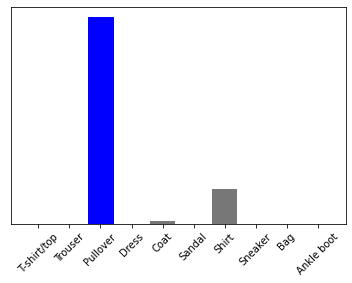

In [39]:
plot_value_array(1, predictions_single[0], test_labels)
_ = plt.xticks(range(10), class_names, rotation=45)
plt.show()

In [40]:
np.argmax(predictions_single[0])

2